# Adapter 전문가 제거 실험

알고리즘별 단일 탐지기의 피처 추가 전·후 비교. 기존 벤치마크와 v18 모델은 보존한다.

## 1. 무엇을 비교했나

- 기존 피처 28개 대 Adapter 파생 피처 10개 추가
- IF·K-means·LOF 각각 탐지기 하나, 전문가/Adapter별 threshold 없음
- 정상 개발 상위 3%로 경보 기준을 고정한 뒤 기존 테스트 전수 평가
- 통계는 정상 학습에서만 계산. 최종 테스트로 튜닝하지 않음

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'reports/adapter_feature_ablation/summary.json').exists())
OUT = ROOT/'reports/adapter_feature_ablation'
result = json.loads((OUT/'summary.json').read_text(encoding='utf-8'))
frozen = json.loads((OUT/'frozen.json').read_text(encoding='utf-8'))
metrics = ['accuracy','precision','recall','f1','normal_false_positive_rate','average_precision','roc_auc']
def table(rows, columns=metrics):
    data = pd.DataFrame(rows).set_index('method')
    return (data[[c for c in columns if c in data]]*100).round(2)

## 2. 전체 성능

단위 %. 전체 6개 시나리오와 Hard 포함. 오탐률은 낮을수록 좋다. AP는 Average Precision이다.

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,78.04,35.95,31.58,33.62,12.03,34.45,69.20
if_adapter_features,76.48,31.08,27.55,29.21,13.06,30.02,62.99
kmeans_baseline,79.43,38.98,29.70,33.71,9.94,32.77,65.89
kmeans_adapter_features,81.71,18.63,1.13,2.14,1.06,18.82,53.41
lof_baseline,81.98,48.33,32.96,39.19,7.53,45.87,73.45
lof_adapter_features,73.94,16.42,11.73,13.68,12.76,19.09,56.56


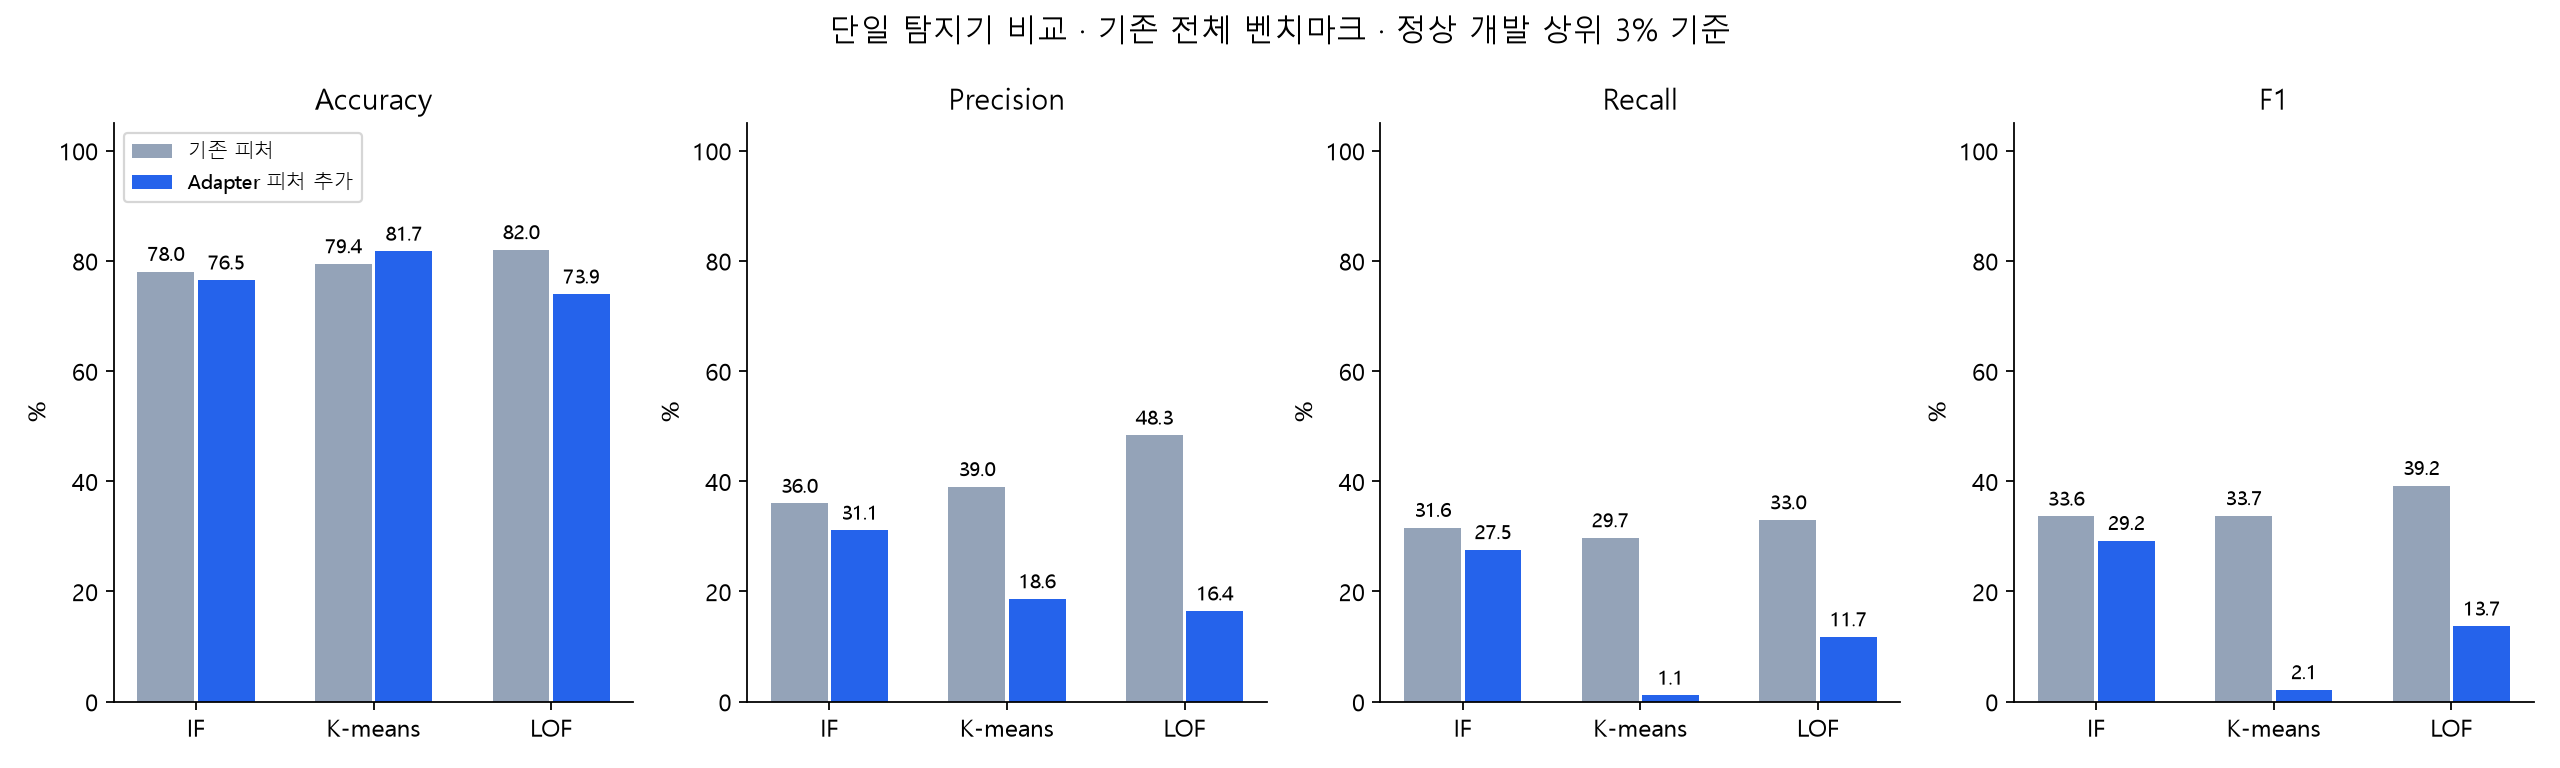

In [2]:
display(table(result['pooled']))
display(Image(filename=str(OUT/'figures/metrics.png')))

## 3. 피처 추가 효과

- Isolation Forest: F1 33.62% → 29.21% (-4.42%p), 정상 오탐률 12.03% → 13.06%
- MiniBatch K-means: F1 33.71% → 2.14% (-31.58%p), 정상 오탐률 9.94% → 1.06%
- LOF: F1 39.19% → 13.68% (-25.51%p), 정상 오탐률 7.53% → 12.76%

## 4. 주요 5개 시나리오

컬럼 관계·Hard를 제외한 합산도 별도 제공. 제외된 두 데이터도 삭제하거나 숨기지 않고 다음 셀에서 확인한다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if_baseline,79.06,37.24,31.60,34.19,11.07
if_adapter_features,77.47,32.03,27.53,29.61,12.14
kmeans_baseline,79.65,39.11,32.76,35.65,10.60
kmeans_adapter_features,82.03,18.63,1.30,2.44,1.18
lof_baseline,82.28,47.97,34.98,40.45,7.89
lof_adapter_features,75.41,14.84,9.05,11.24,10.80


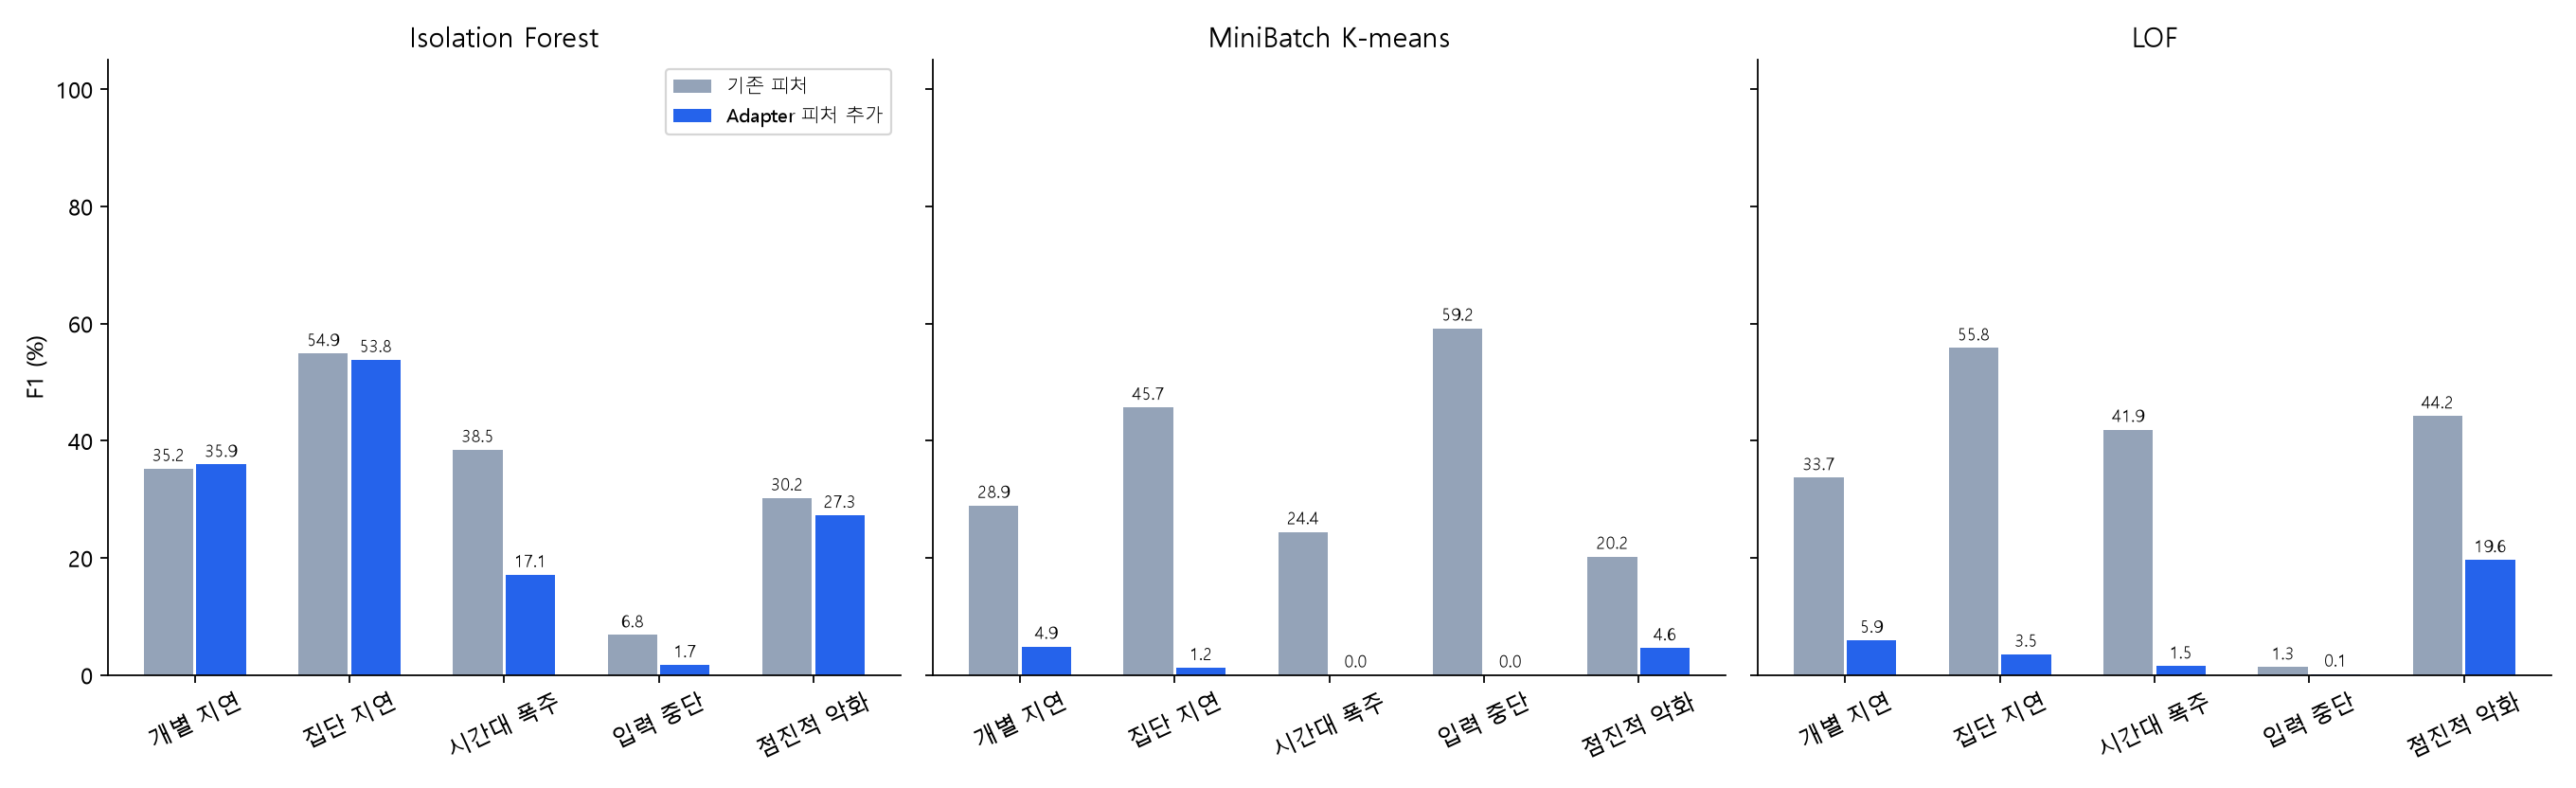

### individual_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,77.87,23.43,70.84,35.22,21.48,31.83,81.79
if_adapter_features,76.73,23.44,76.81,35.92,23.28,35.27,83.39
kmeans_baseline,76.01,19.32,57.51,28.93,22.28,20.75,73.41
kmeans_adapter_features,90.42,15.49,2.89,4.87,1.46,15.80,71.42
lof_baseline,83.36,25.45,49.73,33.67,13.52,23.26,79.35
lof_adapter_features,83.09,5.61,6.26,5.92,9.78,13.63,71.93


### group_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,79.26,40.93,83.19,54.86,21.44,58.74,87.27
if_adapter_features,78.07,39.51,84.33,53.81,23.05,55.60,87.05
kmeans_baseline,76.50,35.15,65.21,45.67,21.48,47.12,80.37
kmeans_adapter_features,83.04,5.27,0.70,1.24,2.26,19.53,62.49
lof_baseline,81.31,43.47,77.90,55.80,18.08,76.00,87.95
lof_adapter_features,68.15,3.26,3.85,3.53,20.37,15.48,56.60


### column_relation

...

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,80.90,15.26,4.39,6.82,4.62,22.88,70.08
if_adapter_features,79.63,3.69,1.11,1.71,5.50,13.57,47.10
kmeans_baseline,89.63,79.26,47.24,59.19,2.34,61.84,81.50
kmeans_adapter_features,84.08,0.00,0.00,0.00,0.00,13.31,45.43
lof_baseline,83.42,12.65,0.71,1.34,0.92,37.39,80.97
lof_adapter_features,83.70,2.89,0.07,0.14,0.46,15.23,53.30


### gradual_degradation

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,71.45,38.56,24.83,30.21,13.10,34.12,60.34
if_adapter_features,69.49,33.50,22.97,27.25,15.10,31.19,58.50
kmeans_baseline,67.55,26.05,16.54,20.23,15.55,26.68,52.19
kmeans_adapter_features,73.90,25.42,2.53,4.60,2.46,26.78,50.09
lof_baseline,76.64,54.48,37.19,44.20,10.29,49.21,65.44
lof_adapter_features,63.07,21.42,18.14,19.64,22.04,24.77,50.52


### mixed_hard

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,69.05,29.92,29.14,29.53,19.53,31.94,57.90
if_adapter_features,65.10,25.26,29.04,27.01,24.59,29.81,55.77
kmeans_baseline,75.86,31.69,7.38,11.97,4.55,25.04,53.71
kmeans_adapter_features,77.75,0.00,0.00,0.00,0.00,22.97,52.22
lof_baseline,78.42,53.99,20.17,29.37,4.92,40.63,60.67
lof_adapter_features,58.76,20.03,28.54,23.54,32.59,19.40,41.66


In [3]:
display(table(result['main_five_pooled']))
display(Image(filename=str(OUT/'figures/scenario_f1.png')))
for dataset in result['datasets']:
    display(Markdown('### '+dataset['dataset']))
    display(table(dataset['metrics']))

## 5. 실제 threshold와 오탐 목표 민감도

score > threshold면 경보. 점수는 확률이 아니다. 1%·3%·5%는 정상 개발에서 설정한 목표이며, 테스트 오탐률을 보장하지 않는다.

In [4]:
display(pd.DataFrame([{'method':m['method'],**m['thresholds']} for m in frozen['models']]))
for rate, rows in result['sensitivity'].items():
    display(Markdown('### 정상 개발 오탐 목표 '+str(float(rate)*100)+'%'))
    display(table(rows))

,method,0.01,0.03,0.05
0,if_baseline,0.579468,0.544249,0.531244
1,if_adapter_features,0.602185,0.576150,0.559491
2,kmeans_baseline,1.855743,1.366823,1.241887
3,kmeans_adapter_features,317.385218,317.366428,268.307224
4,lof_baseline,3.661485,2.536106,2.272822
5,lof_adapter_features,162.123505,130.084244,100.608719


### 정상 개발 오탐 목표 1.0%

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if_baseline,81.24,42.74,19.17,26.47,5.49
if_adapter_features,80.39,38.90,19.83,26.27,6.66
kmeans_baseline,82.73,52.80,18.55,27.45,3.55
kmeans_adapter_features,82.29,38.47,0.94,1.84,0.32
lof_baseline,84.43,64.77,25.43,36.52,2.96
lof_adapter_features,74.61,16.60,10.97,13.21,11.79


### 정상 개발 오탐 목표 3.0%

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if_baseline,78.04,35.95,31.58,33.62,12.03
if_adapter_features,76.48,31.08,27.55,29.21,13.06
kmeans_baseline,79.43,38.98,29.70,33.71,9.94
kmeans_adapter_features,81.71,18.63,1.13,2.14,1.06
lof_baseline,81.98,48.33,32.96,39.19,7.53
lof_adapter_features,73.94,16.42,11.73,13.68,12.76


### 정상 개발 오탐 목표 5.0%

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if_baseline,75.52,33.04,37.96,35.33,16.45
if_adapter_features,73.42,28.32,33.24,30.58,17.99
kmeans_baseline,78.69,37.89,32.83,35.18,11.51
kmeans_adapter_features,81.26,18.45,1.86,3.38,1.76
lof_baseline,80.43,43.53,37.41,40.24,10.38
lof_adapter_features,72.52,16.86,14.24,15.44,15.02


## 6. 점수 분포와 경보선

일반 막대 히스토그램. 정상/이상 각각 표본 내 비중. 극단 꼬리는 표시 범위 밖 비중으로 명시. 표본 그림과 전수 지표를 혼동하지 않는다.

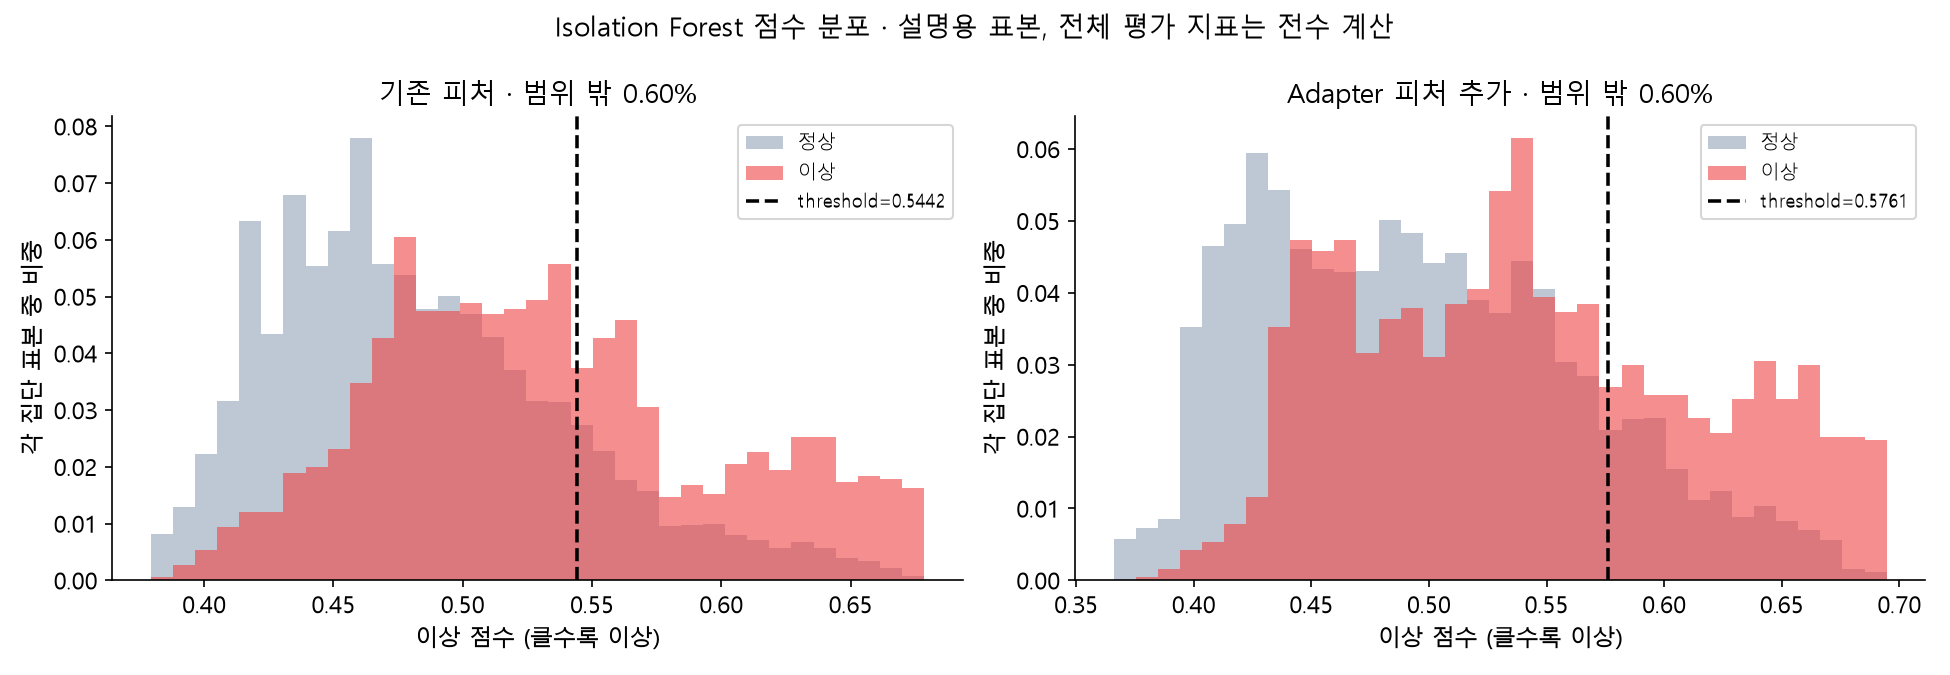

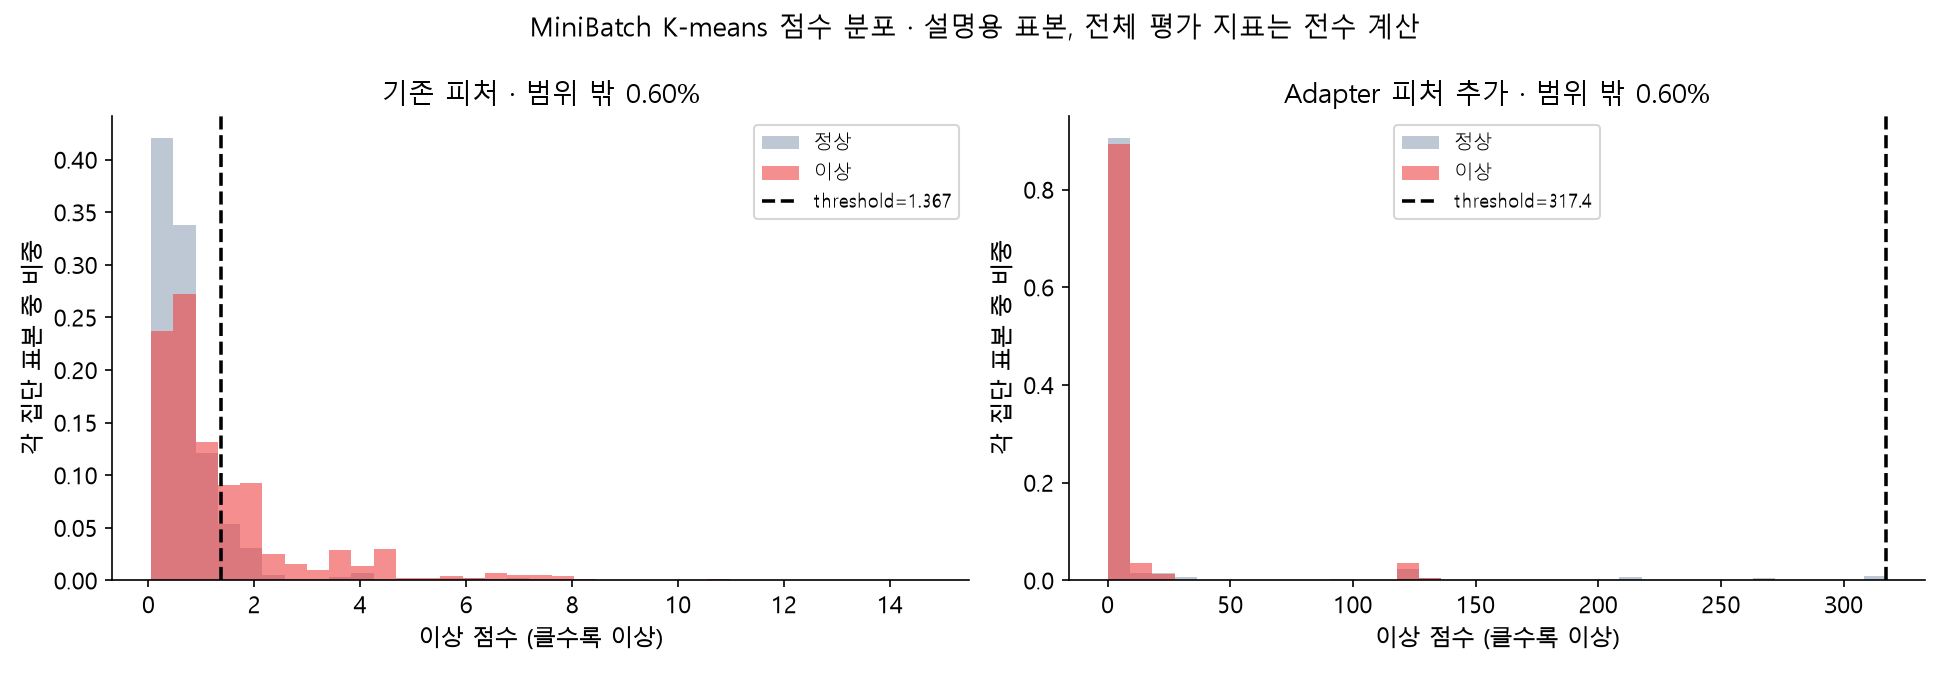

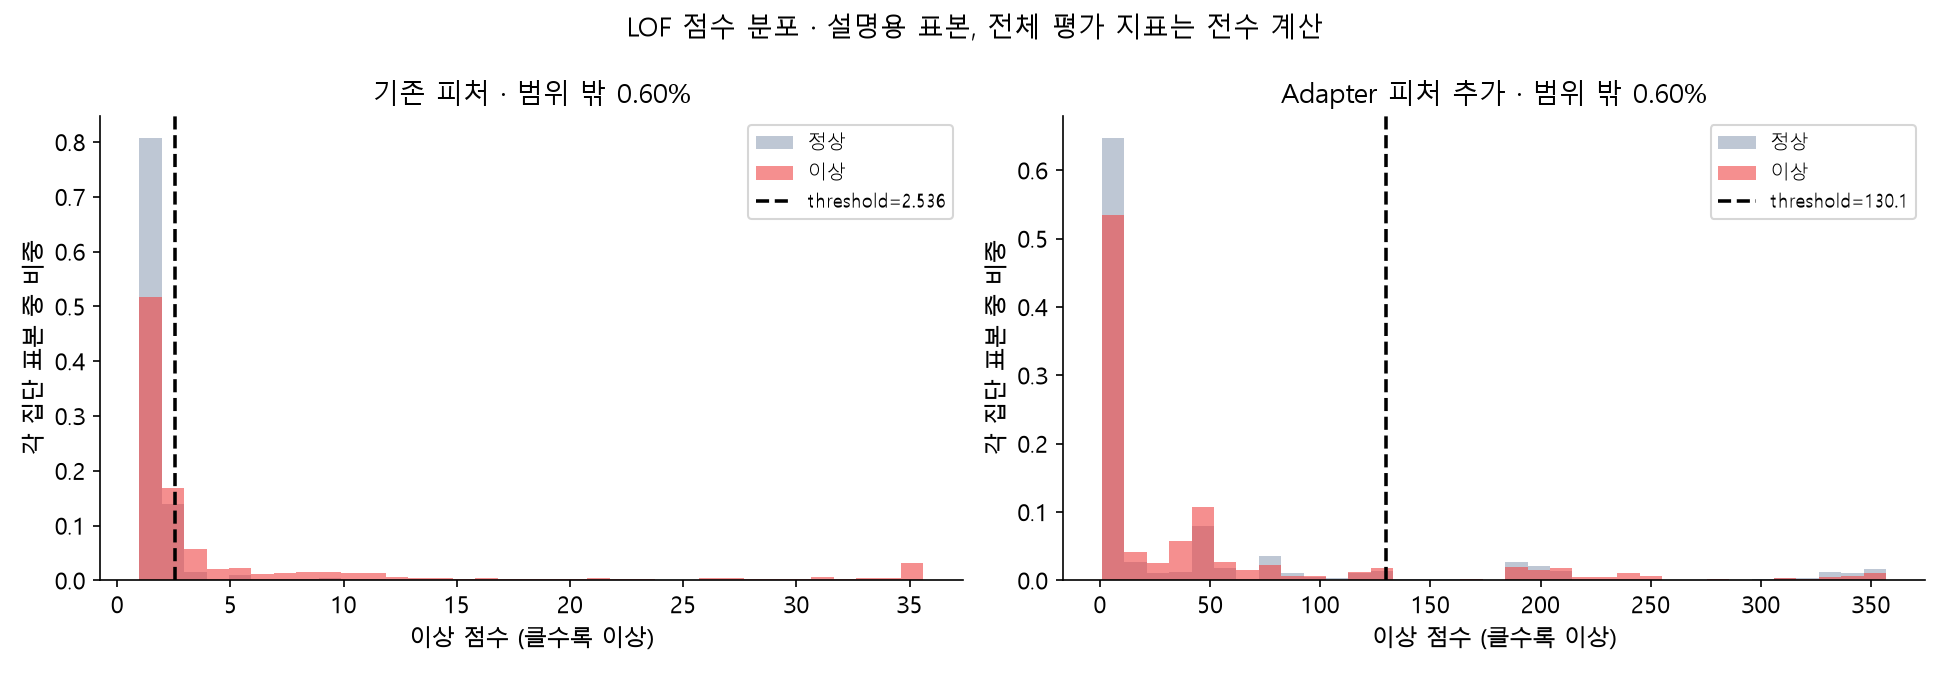

In [5]:
for algorithm in ['if','kmeans','lof']:
    display(Image(filename=str(OUT/'figures'/f'{algorithm}_scores.png')))

## 7. 추가된 Adapter 피처

정상 학습에서 만든 참고 통계이며 별도 전문가 모델이 아니다. Adapter 전체 요청 수가 아니라 Process 스트림의 Adapter 기준 편차다.

In [6]:
display(pd.Series(frozen['added_feature_descriptions'],name='의미').to_frame())
display(pd.DataFrame([{'method':m['method'],'피처 수':len(m['columns']),'학습 분':m['fit_rows'],'탐지기 수':m['estimator_count']} for m in frozen['models']]))

,의미
adapter_max_duration_z,1분 최대 log 소요시간의 Adapter 과거 중앙값 대비 편차 / IQR
adapter_p95_upper_tail,최근 5분 P95가 같은 Adapter의 정상 5분 P95 분포에서 드물게 큰 정도
adapter_count_p95_z,Adapter + 최근 5분 평균 totalCount 구간 기준 log P95 편차...
adapter_count_p95_upper_tail,동일 Adapter·처리건수 구간에서 5분 P95가 드물게 큰 정도
adapter_count_p95_lower_tail,동일 Adapter·처리건수 구간에서 5분 P95가 드물게 작은 정도
adapter_workload_z,최근 5분 평균 totalCount의 Adapter 기준 편차 / IQR
adapter_stream_arrivals_z,현재 Process 스트림의 1분 실행 횟수를 Adapter·요일유형·시간대 정상 ...
adapter_reference_log_duration,해당 Adapter·처리건수 구간의 정상 5분 log P95 중앙값
adapter_delay_short_long,처리건수 보정 지연의 최근 5분 평균 - 15분 평균
adapter_delay_ewma,처리건수 보정 지연의 양수 부분 EWMA(alpha=0.2)


,method,피처 수,학습 분,탐지기 수
0,if_baseline,28,19793,1
1,if_adapter_features,38,19793,1
2,kmeans_baseline,28,19793,1
3,kmeans_adapter_features,38,19793,1
4,lof_baseline,28,2048,1
5,lof_adapter_features,38,2048,1


## 8. 오탐·미탐 사례 읽기

TP=맞힌 이상, FP=오탐, FN=놓친 이상. 피처 값은 단서이며 모델의 인과적 기여도나 장애 원인을 의미하지 않는다.

In [7]:
examples = pd.DataFrame([{'dataset':d['dataset'],**e} for d in result['datasets'] for e in d['examples']])
display(examples[['dataset','method','outcome','adapterType','processId','score','threshold','zero_run','arrival_dev_1m','adapter_count_p95_z','adapter_stream_arrivals_z']].head(24))

,dataset,method,outcome,adapterType,processId,score,threshold,zero_run,arrival_dev_1m,adapter_count_p95_z,adapter_stream_arrivals_z
0,individual_delay,if_baseline,TP,FILE.READER,IF_FILE2FILE_010_PR001,0.665807,0.544249,0.000000,-0.200000,25.090752,-1.000000
1,individual_delay,if_baseline,FP,FILE.READER,IF_FILE2FILE_010_PR001,0.649125,0.544249,0.693147,-0.400000,25.090752,-2.709511
2,individual_delay,if_baseline,FN,FILE.WRITER,IF_FILE2FILE_008_PR003,0.409716,0.544249,0.000000,0.000000,-1.421614,1.000000
3,individual_delay,if_adapter_features,TP,FILE.READER,IF_FILE2FILE_010_PR001,0.685837,0.576150,0.000000,-0.200000,25.090752,-1.000000
4,individual_delay,if_adapter_features,FP,FILE.READER,IF_FILE2FILE_010_PR001,0.671543,0.576150,0.693147,-0.400000,25.090752,-2.709511
5,individual_delay,if_adapter_features,FN,FILE.WRITER,IF_FILE2FILE_008_PR003,0.435562,0.576150,0.000000,0.000000,-1.421614,1.000000
6,individual_delay,kmeans_baseline,TP,FILE.READER,IF_FILE2FILE_010_PR001,7.142589,1.366823,0.000000,-0.200000,25.090752,-1.000000
7,individual_delay,kmeans_baseline,FP,FILE.READER,IF_FILE2FILE_010_PR001,7.024930,1.366823,0.693147,-0.400000,25.090752,-2.709511
8,individual_delay,kmeans_baseline,FN,FILE.WRITER,IF_FILE2FILE_008_PR003,0.742237,1.366823,0.000000,0.000000,-1.421614,1.000000
9,individual_delay,kmeans_adapter_features,TP,DB.EXECUTOR,IF_DBEXECUTOR_004_PR001,317.792399,317.366428,0.000000,0.000000,20.448211,0.000000


## 9. 기존 v18과 참고 비교

v18은 내부 분기가 여러 개이므로 이번 단일 탐지기와 구조가 다르다. 여기서는 모델 대체 가능성을 보는 참고 비교이며 피처 효과만의 공정한 비교는 아니다.

In [8]:
old = json.loads((ROOT/'reports/model_research_v18/evaluation_4f5469a098b82372/summary.json').read_text(encoding='utf-8'))
display(table([r for r in old['pooled'] if r['method'].endswith(('_global','_ensemble'))]))

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if_global,86.13,74.05,32.73,45.39,2.45
if_ensemble,86.28,72.45,35.65,47.78,2.90
kmeans_global,85.17,65.52,33.35,44.20,3.75
kmeans_ensemble,84.97,63.16,35.18,45.19,4.39
lof_global,84.58,61.39,33.61,43.44,4.52
lof_ensemble,84.25,58.96,34.92,43.86,5.20


## 10. 정상 데이터에서 피처가 안정적인가?

추가한 Adapter 처리건수 편차는 학습에서 거의 상수인 구간이 많아 스케일 하한 0.05가 적용되었다. 정상 개발에서 정규화 크기가 커지고 거리 기반 모델의 경보선이 높아지는 현상이 함께 나타났다. 인과적 피처 기여도를 확정한 것은 아니다. 정상 처리건수 변화가 반드시 장애는 아니므로, 향후 이 피처 제외/안정적 스케일링을 별도 검증할 필요가 있다.

In [9]:
shift = json.loads((OUT/'normal_shift_diagnostics.json').read_text(encoding='utf-8'))
display(pd.DataFrame(shift['feature_scale_shift']))
display(pd.DataFrame(shift['score_shift']))

,feature,encoder_scale,train_abs_scaled_p95,normal_calibration_abs_scaled_p95,normal_calibration_abs_scaled_p99,normal_calibration_fraction_abs_scaled_gt_20
0,adapter_workload_z,0.050000,15.129416,921.047424,1081.577148,0.346220
1,adapter_max_duration_z,1.000000,1.169243,14.679611,16.184662,0.006471
2,adapter_delay_ewma,0.876640,1.140719,3.966594,16.174149,0.000000
3,adapter_count_p95_z,1.726341,1.334773,9.132656,14.918195,0.002287
4,adapter_delay_short_long,0.102871,4.176075,2.983932,7.771777,0.000167
5,adapter_count_p95_upper_tail,1.139429,1.445687,5.683337,6.535698,0.000000
6,adapter_p95_upper_tail,1.479913,1.052806,4.336154,4.992413,0.000000
7,adapter_count_p95_lower_tail,1.691538,1.183678,4.119275,4.513824,0.000000
8,adapter_stream_arrivals_z,1.834044,0.932100,0.545243,0.932100,0.000000
9,adapter_reference_log_duration,2.980179,0.790342,0.790203,0.790342,0.000000


,method,train_score_p95,normal_calibration_score_p95,normal_calibration_score_p99,threshold
0,if_baseline,0.516168,0.531234,0.579450,0.544249
1,if_adapter_features,0.503446,0.559483,0.602183,0.576150
2,kmeans_baseline,1.000080,1.241886,1.855732,1.366823
3,kmeans_adapter_features,1.000118,268.307224,317.385218,317.366428
4,lof_baseline,2.332013,2.272626,3.656915,2.536106
5,lof_adapter_features,3.183628,100.603767,162.119385,130.084244


## 11. 결론을 적용할 범위

- 1회 고정 seed 비교이며 통계적 우월성을 확정하지 않는다.
- 기존 피처에도 Adapter 조건부 정보가 있으므로 정보가 전혀 없는 모델과 비교한 것은 아니다.
- 동시 Process 집단/Adapter 전체 트래픽은 현재 독립 재생 사례로 검증하지 못한다.
- S 정상 후보, 합성 트래픽 prior, 같은 합성 생성기라는 제한이 있다.
- 피처가 안 좋아진 결과도 그대로 보존하며 기존 v18 교체/배포를 수행하지 않는다.
- ADBench 검토는 같은 폴더 ADBENCH.md. 기존 데이터/운영 모델/Notion/GitHub는 변경하지 않았다.